In [1]:
import sys
sys.path.append("../src")

import numpy as np
from outcomes import draw_outcome, net_tvpi, simulate_fund

print(net_tvpi(2.75))   # expected: 1.96

1.96


In [2]:
gross = []
net = []
for i in range(10000):
    g = simulate_fund(30)          # gross multiple on invested capital
    gross.append(g)
    net.append(net_tvpi(g))        # what LPs actually receive
gross = np.array(gross)
net = np.array(net)

print("Mean  | gross:", gross.mean().round(2), "| net:", net.mean().round(2))
print("P(<1x)| gross:", (gross < 1).mean(), "| net:", (net < 1).mean())
print("P(3x) | gross:", (gross >= 3).mean(), "| net:", (net >= 3).mean())

Mean  | gross: 2.76 | net: 1.96
P(<1x)| gross: 0.0683 | net: 0.1535
P(3x) | gross: 0.3643 | net: 0.1609


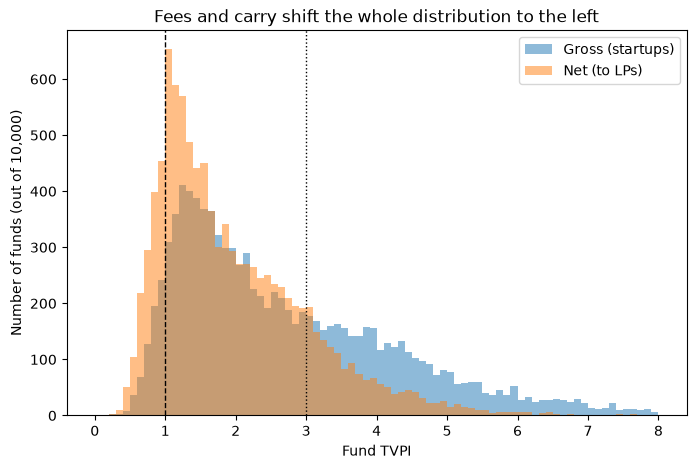

In [3]:
import matplotlib.pyplot as plt

bins = np.linspace(0, 8, 81)
plt.figure(figsize=(8, 5))
plt.hist(gross, bins=bins, alpha=0.5, label="Gross (startups)")
plt.hist(net, bins=bins, alpha=0.5, label="Net (to LPs)")
plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.axvline(3, color="black", linestyle=":", linewidth=1)
plt.xlabel("Fund TVPI")
plt.ylabel("Number of funds (out of 10,000)")
plt.title("Fees and carry shift the whole distribution to the left")
plt.legend()
plt.savefig("../results/phase3_gross_vs_net.png", dpi=150, bbox_inches="tight")
plt.show()

## What this means

**From gross to net.** Phases 1 and 2 measured what startups return (gross). LPs receive less, because the manager charges a 2% annual management fee for 10 years and keeps 20% of the profits as carried interest. Out of a EUR 120M fund, only EUR 96M is actually invested.

| Fund of 30 startups | Gross | Net to LPs |
|---|---|---|
| Mean TVPI | 2.76x | 1.96x |
| P(TVPI < 1x) | 6.8% | 15.4% |
| P(TVPI ≥ 3x) | 36.4% | 16.1% |

**Findings.**
- Fees and carry take about 0.8x of the average multiple.
- The chance of losing money more than doubles, and the chance of 3x is more than halved.
- The bar rises on both sides: startups must return 1.25x for LPs to break even, and about 4.4x for LPs to get 3x.
- The net distribution is shifted left and compressed. Above break-even, every extra 1x gross becomes only about 0.64x net, because carry takes a share of the best outcomes.

**Why it matters.** A net 1.96x over about 10 years is roughly 7% a year, comparable to public equities but locked up and far riskier. LPs therefore invest in VC only if they expect to beat the average, which means paying for manager selection, not for access to the asset class.

**Simplifications.** The fee is a flat 2% on committed capital for 10 years. Many funds lower it after the investment period, and real funds hold reserves for follow-on rounds. Both are possible extensions.